# MS-DSA-NET — этап 2b: дообучение с IDEAS + пациенты без FCD + ансамбль + рабочая точка

**Цель:** находить FCD, если он есть, при минимуме ложных срабатываний

| Что добавлено | Зачем |
|---|---|
| **5-fold CV на 34 FCD IDEAS** (слабая разметка резекций) + 85 FCD UHB | целевой домен (GE, 2D FLAIR) в обучении; каждый пациент тестируется моделью, которая его не видела |
| **Пациенты без FCD в обучении:** 60 IDEAS с другой патологией (вне резекции = фон) + здоровые UHB | учит «молчать», где FCD нет — главный рычаг против ложных |
| **Отложенные пациенты без FCD (≈45)** — не участвуют ни в чём, кроме проверки | честная оценка ложных срабатываний на новых людях — раньше её не было вовсе |
| **Ансамбль 5 моделей фолдов + Nyúl + TTA** | итоговая модель для новых данных: усреднение снижает ложные и разброс |
| **Рабочая точка:** порог выбирается на половине отложенных отрицательных, отчёт — на другой половине | порог под заданный уровень ложных, без подгонки под отчётные данные |
| **Контроль входа:** толщина FLAIR, разрешение T1, качество регистрации | на неподходящих данных модель предупреждает, а не молча ошибается |
| **`deploy/` + `predict_new()`** | готовый вызов для свежих пациентов: QC → вероятности → таблица кандидатов |

Без подглядывания в тест: число эпох фиксировано, модель фолда — EMA весов в конце; эталон Nyúl — только UHB.

**Порядок:** `SMOKE = True` (≈30–40 мин: подготовка отрицательных + 1 короткий фолд) → `SMOKE = False`, Restart → запуск в tmux (`nbconvert`).
**Время полного прогона:** ≈ 9–10 ч (подготовка ≈ 40 мин, 5 фолдов × ≈1.7 ч, оценка ≈ 40 мин). Прерывание безопасно — продолжит с места остановки.

## 1. Конфигурация

In [3]:
import os, sys, time, json, subprocess, warnings
from pathlib import Path
os.nice(15)
try:
    import psutil; psutil.Process().ionice(psutil.IOPRIO_CLASS_IDLE)
except Exception as e: print("ionice:", e)
FSLDIR, VENV_BIN = Path.home() / "fsl", Path(sys.executable).parent
os.environ.update(FSLDIR=str(FSLDIR), FSLOUTPUTTYPE="NIFTI_GZ")
_p = [p for p in os.environ["PATH"].split(":") if p and p not in (str(VENV_BIN), f"{FSLDIR}/bin", f"{FSLDIR}/share/fsl/bin")]
os.environ["PATH"] = ":".join([str(VENV_BIN)] + _p + [f"{FSLDIR}/share/fsl/bin", f"{FSLDIR}/bin"])
warnings.filterwarnings("ignore", message=".*unable to generate class balanced samples.*")
warnings.filterwarnings("ignore", category=FutureWarning)

PROJ    = Path.home() / "projects/mri/ms_dsa_net"
REPO    = PROJ / "MS-DSA-NET"
WEIGHTS = REPO / "pretrained/model.pth"
MNI     = REPO / "inputs/MNI152_T1_1mm.nii.gz"

SMOKE = False                                  

# ресурсы
GPU_ID = 1
GPU_TEMP_PAUSE, GPU_TEMP_RESUME, TEMP_CHECK_EVERY = 80, 72, 10
NUM_WORKERS, N_FSL = 4, 5

# данные без FCD
N_NEG_IDEAS_TRAIN, N_NEG_IDEAS_TEST = 60, 30  # IDEAS с другой патологией (без упоминания FCD)
N_HC_TRAIN, N_HC_TEST = 40, 15                # здоровые контроли UHB
TARGET_FP_NEG = 0.3                           # целевое среднее число ложных кластеров на пациента без FCD

# обучение
K_FOLDS, SEED   = 5, 0
EPOCHS, EPOCH_ITEMS = 30, 180                 # фиксировано заранее; 180 случаев за эпоху (взвешенная выборка)
W_IDEAS_FCD, NEG_SHARE = 2.0, 0.25            # вес FCD IDEAS относительно UHB; доля отрицательных в эпохе
LR, WD          = 1e-4, 1e-5
PATCHES_PER_CASE, ACCUM = 4, 1                # 7.8 ГБ; при нехватке памяти: 2 и 2
AMP, EMA_DECAY  = True, 0.998
LAMBDA_MIL, MIL_K, RING_MM = 0.5, 100, 3
THICK_PROB, THICK_RANGE = 0.5, (2.0, 6.0)
PATCH, OVERLAP  = (128, 128, 128), 0.25

CKPT = PROJ / ("checkpoints/stage2b_smoke" if SMOKE else "checkpoints/stage2b"); CKPT.mkdir(parents=True, exist_ok=True)
SPLITS = PROJ / "checkpoints/stage2b_splits.json"
VARIANT = "cv2b_smoke" if SMOKE else "cv2b_nyul_tta"
os.environ["CUDA_DEVICE_ORDER"] = "PCI_BUS_ID"
os.environ["CUDA_VISIBLE_DEVICES"] = str(GPU_ID)
for p in (Path.cwd(), PROJ):
    if (p / "msdsa_lib.py").exists() and str(p) not in sys.path: sys.path.insert(0, str(p))
import msdsa_lib as ml
assert hasattr(ml, "cluster_table") and hasattr(ml, "index_without_masks"), "Обновите msdsa_lib.py до последней версии"
mem = int(next(l for l in open("/proc/meminfo") if l.startswith("MemAvailable")).split()[1]) / 2**20
print("SMOKE" if SMOKE else "Полный прогон", f"| GPU {GPU_ID} | RAM доступно {mem:.0f} ГБ")
if mem < 12: print("RAM мало — уменьшить N_NEG_IDEAS_TRAIN / N_HC_TRAIN")

Полный прогон | GPU 1 | RAM доступно 118 ГБ


## 2. Окружение, модель, наборы, разбиения

In [4]:
import numpy as np, pandas as pd, nibabel as nib, torch, monai
import torch.nn.functional as F
import matplotlib.pyplot as plt
from scipy import ndimage
from concurrent.futures import ThreadPoolExecutor
from monai.inferers import sliding_window_inference
torch.set_num_threads(2)
sys.path.insert(0, str(REPO))
from networks2 import MS_DSA_NET
device = torch.device("cuda")
free, total = torch.cuda.mem_get_info()
print(torch.cuda.get_device_name(0), f"| свободно {free/2**30:.1f} / {total/2**30:.1f} ГБ")

PAUSE_SEC = [0.0]
def gpu_temp():
    out = subprocess.run(["nvidia-smi", "-i", str(GPU_ID), "--query-gpu=temperature.gpu", "--format=csv,noheader,nounits"],
                         capture_output=True, text=True).stdout.strip()
    return int(out) if out.isdigit() else -1
def wait_cool():
    if gpu_temp() >= GPU_TEMP_PAUSE:
        t0 = time.time()
        while gpu_temp() > GPU_TEMP_RESUME: time.sleep(10)
        PAUSE_SEC[0] += time.time() - t0

def build_model():
    return MS_DSA_NET(spatial_dims=3, in_channels=2, out_channels=2, img_size=list(PATCH), feature_size=16, pos_embed=True,
                      project_size=64, sa_type="parallel", norm_name="instance",
                      act_name=("leakyrelu", {"inplace": True, "negative_slope": 0.01}), res_block=True, bias=False, dropout_rate=0.1)
def load_weights(m, path):
    sd = torch.load(path, map_location="cpu"); sd = sd.get("model", sd.get("state_dict", sd))
    m.load_state_dict({k.replace("module.", "", 1): v for k, v in sd.items()}, strict=True); return m
def make_run_sw(m):
    def run_sw(x, sw):
        with torch.no_grad(), torch.autocast("cuda", enabled=AMP):
            return sliding_window_inference(x, PATCH, sw, m, overlap=OVERLAP)
    return run_sw

# ---- UHB: FCD и здоровые ----
UHB = ml.Dataset("UHB", "ds004199", PROJ / "data/ds004199", PROJ / "work_uhb", PROJ / "outputs_uhb", gt_space="flair")
uhb_keys = ml.s3_index(UHB.s3_id, UHB.data_dir / "_s3_index.txt")
UHB.files = {**ml.index_without_masks(uhb_keys), **ml.index_with_masks_in_s3(uhb_keys)}
uhb_fcd = sorted(p.name for p in (UHB.work_dir / "fsl").iterdir()
                 if (p / "gt_reg.nii.gz").exists() and (p / "t1_reg_brain_mask.nii.gz").exists())
hc_pool = sorted(s for s, f in UHB.files.items() if f["mask"] is None)

# ---- IDEAS: FCD и другая патология ----
meta = pd.read_csv(PROJ / "data/ideas_meta/Metadata_Release_Anon.csv"); meta["sub"] = "sub-" + meta["ID"].astype(str)
meta = meta.drop_duplicates("sub").set_index("sub")
meta["fcd_any"] = (meta.Pathology == "FCD") | meta["OP MEMO"].fillna("").str.contains(r"FCD|dysplas", case=False)
fcd = meta.index[meta.Pathology == "FCD"].tolist()
mask_fn = lambda s: (lambda p: p if p.exists() else None)(PROJ / "data/ideas_masks/masks" / s[4:] / f"{s[4:]}_MaskInRawData.nii.gz")
IDEAS = ml.Dataset("IDEAS", "ds005602", PROJ / "data/ds005602", PROJ / "work", PROJ / "outputs", gt_space="t1")
IDEAS.files = ml.index_with_local_masks(ml.s3_index(IDEAS.s3_id, IDEAS.data_dir / "_s3_index.txt"), meta.index.tolist(), mask_fn)
ideas_fcd = [s for s in fcd if (IDEAS.fsl(s) / "gt_reg.nii.gz").exists() and (IDEAS.fsl(s) / "t1_reg_brain_mask.nii.gz").exists()]
neg_pool = sorted(s for s in meta.index[~meta.fcd_any] if IDEAS.files[s]["flair"] and IDEAS.files[s]["t1"])

# ---- разбиения (фиксируются в файл один раз) ----
def flair_thick(ds, s): return max(nib.load(ml._local(ds, ds.files[s]["flair"])).header.get_zooms()[:3])
thick = {s: "5 мм" if flair_thick(IDEAS, s) >= 4.5 else "≤3.5 мм" for s in ideas_fcd}
if SPLITS.exists():
    SPL = json.load(open(SPLITS))
else:
    rng = np.random.default_rng(SEED)
    neg = rng.permutation(neg_pool).tolist(); hc = rng.permutation(hc_pool).tolist()
    SPL = dict(folds=ml.make_folds(ideas_fcd, [thick[s] for s in ideas_fcd], K_FOLDS, SEED),
               neg_train=neg[:N_NEG_IDEAS_TRAIN], neg_test=neg[N_NEG_IDEAS_TRAIN:N_NEG_IDEAS_TRAIN + N_NEG_IDEAS_TEST],
               hc_train=hc[:N_HC_TRAIN], hc_test=hc[N_HC_TRAIN:N_HC_TRAIN + N_HC_TEST])
    SPLITS.parent.mkdir(parents=True, exist_ok=True); json.dump(SPL, open(SPLITS, "w"), indent=1)
FOLDS = SPL["folds"]
print(f"FCD: UHB {len(uhb_fcd)}, IDEAS {len(ideas_fcd)} | без FCD: IDEAS {len(neg_pool)} (обуч. {len(SPL['neg_train'])}, тест {len(SPL['neg_test'])}),"
      f" здоровые UHB {len(hc_pool)} (обуч. {len(SPL['hc_train'])}, тест {len(SPL['hc_test'])})")
display(pd.crosstab(pd.Series(FOLDS, name="фолд"), pd.Series(thick, name="FLAIR")))
display(meta.loc[SPL["neg_train"] + SPL["neg_test"], "Pathology"].value_counts().to_frame("IDEAS без FCD"))

ref_file = PROJ / "checkpoints/nyul_ref_uhb.npy"
if ref_file.exists(): NYUL_REF = np.load(ref_file)
else: NYUL_REF, _ = ml.nyul_reference(UHB, uhb_fcd); np.save(ref_file, NYUL_REF)
NYUL = ml.Nyul(NYUL_REF)
orig = load_weights(build_model(), WEIGHTS).to(device).eval()
infer_orig = ml.make_infer(make_run_sw(orig), device, 4)
infer_orig_tta = ml.make_infer(make_run_sw(orig), device, 4, tta=True)

NVIDIA RTX A4000 | свободно 14.4 / 14.6 ГБ
FCD: UHB 85, IDEAS 34 | без FCD: IDEAS 359 (обуч. 60, тест 30), здоровые UHB 85 (обуч. 40, тест 15)


FLAIR,5 мм,≤3.5 мм
фолд,,
0,4,3
1,4,3
2,3,4
3,3,4
4,3,3


,IDEAS без FCD
Pathology,
HS,47
OTHER,18
CAV,9
DNT,7
DUAL,7
GL,2


## 3. Препроцессинг пациентов без FCD + исходная модель на них  
Скачивание и FSL ≈ 30–40 мин (один раз). Заодно считаются исходная модель и «Nyúl+TTA» на отложенных — для сравнения.

In [5]:
neg_ideas = SPL["neg_train"] + SPL["neg_test"]; hc_all = SPL["hc_train"] + SPL["hc_test"]
if SMOKE: neg_ideas, hc_all = SPL["neg_train"][:3] + SPL["neg_test"][:2], SPL["hc_train"][:3] + SPL["hc_test"][:2]
kw = dict(mni=MNI, n_fsl=N_FSL, wait_cool=wait_cool)
r1 = ml.run_pipeline(IDEAS, neg_ideas, infer=infer_orig, variant="pred", **kw)
r2 = ml.run_pipeline(UHB, hc_all, infer=infer_orig, variant="base", **kw)
for r in (r1, r2):
    if r["failures"]: display(pd.Series(r["failures"], name="ошибка").head(20))
ok = lambda ds, subs: [s for s in subs if (ds.fsl(s) / "t1_reg_brain_mask.nii.gz").exists() and (ds.fsl(s) / "flair_reg.nii.gz").exists()]
NEG_TRAIN = [(IDEAS, s) for s in ok(IDEAS, SPL["neg_train"])] + [(UHB, s) for s in ok(UHB, SPL["hc_train"])]
NEG_TEST  = [(IDEAS, s) for s in ok(IDEAS, SPL["neg_test"])] + [(UHB, s) for s in ok(UHB, SPL["hc_test"])]
for ds, subs in ((IDEAS, [s for d, s in NEG_TEST if d is IDEAS]), (UHB, [s for d, s in NEG_TEST if d is UHB])):
    ml.run_pipeline(ds, subs, infer=infer_orig_tta, harmonizer=NYUL, variant="nyul_tta", progress=False, **kw)
print(f"Без FCD готово: обучение {len(NEG_TRAIN)}, отложенный тест {len(NEG_TEST)}")

pred: 1 download:   0%|          | 0/90 [00:00<?, ?it/s]

pred: 2 FSL:   0%|          | 0/90 [00:00<?, ?it/s]

pred: 3 GPU:   0%|          | 0/90 [00:00<?, ?it/s]

pred: 4 save:   0%|          | 0/90 [00:00<?, ?it/s]

[IDEAS/pred] 18.4 мин | готово 90 | ошибок 0


base: 1 download:   0%|          | 0/55 [00:00<?, ?it/s]

base: 2 FSL:   0%|          | 0/55 [00:00<?, ?it/s]

base: 3 GPU:   0%|          | 0/55 [00:00<?, ?it/s]

base: 4 save:   0%|          | 0/55 [00:00<?, ?it/s]

[UHB/base] 19.1 мин | готово 55 | ошибок 0
[IDEAS/nyul_tta] 2.0 мин | готово 30 | ошибок 0
[UHB/nyul_tta] 1.1 мин | готово 15 | ошибок 0
Без FCD готово: обучение 100, отложенный тест 45


## 4. Массивы в RAM (float16)  
Метки: UHB FCD 0/1 · IDEAS FCD 0/2/3 (резекция = MIL, кольцо = игнор) · IDEAS без FCD: резекция и кольцо = игнор (3), остальное фон · здоровые: всё фон.

In [6]:
def prep(ds, sub, kind):
    x, gt, brain, _ = ml.load_arrays(ds, sub)
    if ds is IDEAS: x = NYUL(x, brain)
    if kind == "uhb_fcd": lab = gt.astype(np.uint8)
    elif kind == "ideas_fcd": lab = ml.weak_label(gt, RING_MM)
    elif gt is not None: lab = np.where(ml.weak_label(gt, RING_MM) > 0, 3, 0).astype(np.uint8)
    else: lab = np.zeros(brain.shape, np.uint8)
    return sub, {"image": x.astype(np.float16), "label": lab[None], "sub": sub, "kind": kind}

jobs = ([(UHB, s, "uhb_fcd") for s in (uhb_fcd[:8] if SMOKE else uhb_fcd)] + [(IDEAS, s, "ideas_fcd") for s in ideas_fcd]
        + [(ds, s, "neg") for ds, s in NEG_TRAIN])
t0, PREP = time.time(), {}
with ThreadPoolExecutor(4) as ex:
    for sub, d in ex.map(lambda a: prep(*a), jobs): PREP[sub] = d
gb = sum(d["image"].nbytes + d["label"].nbytes for d in PREP.values()) / 2**30
print(f"Подготовлено {len(PREP)} пациентов за {time.time()-t0:.0f} с, {gb:.1f} ГБ RAM")

Подготовлено 219 пациентов за 64 с, 7.4 ГБ RAM


## 5. Аугментации и функция потерь

In [7]:
from monai.transforms import (Compose, EnsureTyped, RandCropByPosNegLabeld, RandFlipd, RandRotated, RandBiasFieldd,
    RandAdjustContrastd, RandHistogramShiftd, RandShiftIntensityd, RandGaussianNoised, RandomizableTransform, MapTransform)
from monai.data import Dataset, DataLoader
from torch.utils.data import WeightedRandomSampler

class RandThickSliceFLAIRd(RandomizableTransform, MapTransform):
    def __init__(self, keys=("image",), prob=0.5, t_range=(2.0, 6.0), axes=(2, 2, 2, 2, 1)):
        MapTransform.__init__(self, keys); RandomizableTransform.__init__(self, prob); self.t_range, self.axes = t_range, axes
    def __call__(self, data):
        d = dict(data); self.randomize(None)
        if not self._do_transform: return d
        t = self.R.uniform(*self.t_range); ax = int(self.R.choice(self.axes)); img = d["image"]
        new = ml.degrade_axis(np.asarray(img[1].detach().cpu()), t, axis=ax, rng=np.random.default_rng(self.R.randint(1 << 30)))
        img[1] = torch.as_tensor(new); return d

KEYS = ["image", "label"]
train_tf = Compose([
    EnsureTyped(keys=KEYS, data_type="tensor", dtype=torch.float32, track_meta=False),
    RandCropByPosNegLabeld(keys=KEYS, label_key="label", spatial_size=PATCH, pos=1, neg=1,
                           num_samples=PATCHES_PER_CASE, image_key=None, image_threshold=0),
    RandThickSliceFLAIRd(prob=THICK_PROB, t_range=THICK_RANGE),
    RandFlipd(keys=KEYS, spatial_axis=[0], prob=0.5), RandFlipd(keys=KEYS, spatial_axis=[1], prob=0.5),
    RandFlipd(keys=KEYS, spatial_axis=[2], prob=0.5),
    RandRotated(keys=KEYS, range_x=0.26, range_y=0.26, range_z=0.26, mode=("bilinear", "nearest"), prob=0.3),
    RandBiasFieldd(keys=["image"], coeff_range=(0.0, 0.3), prob=0.3),
    RandAdjustContrastd(keys=["image"], gamma=(0.7, 1.5), prob=0.3),
    RandHistogramShiftd(keys=["image"], num_control_points=(5, 10), prob=0.3),
    RandShiftIntensityd(keys=["image"], offsets=0.1, prob=0.5),
    RandGaussianNoised(keys=["image"], std=0.05, prob=0.3),
])

def weak_loss(logits, lab):
    """CE по надёжным вокселям (0/1) + Dice по точным маскам (UHB) + MIL по зоне резекции FCD (IDEAS); 3 = игнор."""
    logits = logits.float(); lab = lab[:, 0].round().long()
    valid = lab <= 1
    ce = F.cross_entropy(logits, (lab == 1).long(), reduction="none")
    ce = (ce * valid).sum() / valid.sum().clamp(min=1)
    p = torch.softmax(logits, 1)[:, 1]
    dice, mil = [], []
    for b in range(p.shape[0]):
        pos = lab[b] == 1
        if pos.any():
            v = valid[b]; pb, tb = p[b][v], pos[v].float()
            dice.append(1 - (2 * (pb * tb).sum() + 1e-5) / (pb.sum() + tb.sum() + 1e-5))
        weak = lab[b] == 2
        if int(weak.sum()) >= MIL_K:
            mil.append(-torch.log(torch.topk(p[b][weak], MIL_K).values.mean().clamp(min=1e-4)))
    zero = logits.sum() * 0
    d = torch.stack(dice).mean() if dice else zero
    m = torch.stack(mil).mean() if mil else zero
    return ce + d + LAMBDA_MIL * m, (float(ce), float(d), float(m))

# самопроверка функции потерь
_l = torch.zeros(2, 2, 16, 16, 16); _y = torch.zeros(2, 1, 16, 16, 16)
_y[0, 0, 4:8, 4:8, 4:8] = 1; _y[1, 0, 2:12, 2:12, 2:12] = 2; _y[1, 0, 1, :, :] = 3
_l[0, 1, 4:8, 4:8, 4:8] = 5; _l[1, 1, 5:7, 5:7, 5:7] = 5
good = weak_loss(_l, _y); _l2 = _l.clone(); _l2[1, 1] = -5; _l2[1, 1, 13:15, 13:15, 13:15] = 5
bad = weak_loss(_l2, _y)
print(f"loss: очаг внутри резекции {good[0]:.3f} | очаг вне резекции {bad[0]:.3f} (должно быть больше)"); assert bad[0] > good[0]

loss: очаг внутри резекции 1.936 | очаг вне резекции 3.856 (должно быть больше)


## 6. Кросс-валидация: обучение фолда → тест на его FCD-пациентах (+ его модель на отложенных без FCD)

In [8]:
from torch.optim.swa_utils import AveragedModel

def fold_items(k):
    tr = [s for s in ideas_fcd if FOLDS[s] != k]
    pos_u = [PREP[s] for s in uhb_fcd if s in PREP]; pos_i = [PREP[s] for s in tr]; neg = [PREP[s] for _, s in NEG_TRAIN if s in PREP]
    w = [1.0] * len(pos_u) + [W_IDEAS_FCD] * len(pos_i)
    w_neg = NEG_SHARE / (1 - NEG_SHARE) * sum(w) / max(len(neg), 1)
    return pos_u + pos_i + neg, w + [w_neg] * len(neg), tr

def train_fold(k):
    fdir = CKPT / f"fold{k}"; fdir.mkdir(exist_ok=True)
    if (fdir / "final.pt").exists(): print(f"Фолд {k}: уже обучен"); return fdir / "final.pt"
    items, weights, tr = fold_items(k)
    sampler = WeightedRandomSampler(weights, num_samples=EPOCH_ITEMS, replacement=True)
    loader = DataLoader(Dataset(items, train_tf), batch_size=1, sampler=sampler, num_workers=NUM_WORKERS,
                        pin_memory=True, persistent_workers=NUM_WORKERS > 0)
    model = load_weights(build_model(), WEIGHTS).to(device).train()
    ema = AveragedModel(model, avg_fn=lambda a, c, n: EMA_DECAY * a + (1 - EMA_DECAY) * c)
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WD)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS, eta_min=LR / 20)
    scaler = torch.cuda.amp.GradScaler(enabled=AMP)
    log, start = [], 1
    if (fdir / "last.pt").exists():
        ck = torch.load(fdir / "last.pt", map_location="cpu")
        model.load_state_dict(ck["model"]); ema.load_state_dict(ck["ema"]); opt.load_state_dict(ck["opt"])
        sched.load_state_dict(ck["sched"]); scaler.load_state_dict(ck["scaler"]); log, start = ck["log"], ck["epoch"] + 1
        print(f"Фолд {k}: продолжаю с эпохи {start}")
    n_neg = sum(1 for i in items if i["kind"] == "neg")
    print(f"Фолд {k}: FCD UHB {sum(1 for i in items if i['kind']=='uhb_fcd')} + IDEAS {len(tr)} | без FCD {n_neg} | эпоха = {EPOCH_ITEMS} случаев")
    for epoch in range(start, EPOCHS + 1):
        t_ep, comps, n_it = time.time(), [], 0; PAUSE_SEC[0] = 0.0
        opt.zero_grad(set_to_none=True)
        for it, batch in enumerate(loader):
            if SMOKE and it >= 15: break
            if it % TEMP_CHECK_EVERY == 0: wait_cool()
            x = batch["image"].to(device, non_blocking=True); y = batch["label"].to(device, non_blocking=True)
            with torch.autocast("cuda", enabled=AMP):
                out = model(x)
            loss, c = weak_loss(out, y)
            if not torch.isfinite(loss): opt.zero_grad(set_to_none=True); continue
            scaler.scale(loss / ACCUM).backward()
            if (it + 1) % ACCUM == 0:
                scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_(model.parameters(), 12.0)
                scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True); ema.update_parameters(model)
            comps.append((float(loss),) + c); n_it += 1
        sched.step()
        cm = np.mean(comps, axis=0)
        rec = dict(epoch=epoch, loss=cm[0], ce=cm[1], dice=cm[2], mil=cm[3], sec_it=(time.time() - t_ep) / max(n_it, 1),
                   pause_s=PAUSE_SEC[0], mem_GB=torch.cuda.max_memory_allocated() / 2**30, temp=gpu_temp())
        log.append(rec)
        torch.save(dict(model=model.state_dict(), ema=ema.state_dict(), opt=opt.state_dict(), sched=sched.state_dict(),
                        scaler=scaler.state_dict(), epoch=epoch, log=log), fdir / "last.pt")
        print(f"  ф{k} эпоха {epoch:3d} | loss {rec['loss']:.3f} (ce {rec['ce']:.3f} dice {rec['dice']:.3f} mil {rec['mil']:.3f})"
              f" | {rec['sec_it']:.2f} с/итер | {rec['mem_GB']:.1f} ГБ | {rec['temp']}°C | паузы {rec['pause_s']:.0f} с", flush=True)
    torch.save({"model": ema.module.state_dict()}, fdir / "final.pt")
    pd.DataFrame(log).to_csv(fdir / "log.csv", index=False)
    del loader, model, ema, opt; torch.cuda.empty_cache()
    return fdir / "final.pt"

def test_fold(k, path):
    m = load_weights(build_model(), path).to(device).eval()
    inf = ml.make_infer(make_run_sw(m), device, 4, tta=True)
    test = [s for s in ideas_fcd if FOLDS[s] == k][: (2 if SMOKE else None)]
    ml.run_pipeline(IDEAS, test, infer=inf, harmonizer=NYUL, variant=VARIANT, mni=MNI, n_fsl=4, wait_cool=wait_cool, progress=False)
    # та же модель фолда на отложенных без FCD — для честного сравнения с её же чувствительностью
    for ds in (IDEAS, UHB):
        subs = [s for d, s in NEG_TEST if d is ds][: (2 if SMOKE else None)]
        ml.run_pipeline(ds, subs, infer=inf, harmonizer=NYUL, variant=f"{VARIANT}_f{k}", mni=MNI, n_fsl=4,
                        wait_cool=wait_cool, progress=False)
    del m; torch.cuda.empty_cache()

T0 = time.time()
for k in ([0] if SMOKE else range(K_FOLDS)):
    t_f = time.time(); path = train_fold(k); test_fold(k, path)
    print(f"Фолд {k} готов за {(time.time()-t_f)/60:.0f} мин; всего {(time.time()-T0)/3600:.2f} ч\n", flush=True)

if SMOKE:
    lg = pd.read_csv(CKPT / "fold0/log.csv"); ep_min = EPOCH_ITEMS * lg.sec_it.iloc[-1] / 60

Фолд 0: FCD UHB 85 + IDEAS 27 | без FCD 100 | эпоха = 180 случаев
  ф0 эпоха   1 | loss 0.489 (ce 0.013 dice 0.291 mil 0.368) | 0.93 с/итер | 8.1 ГБ | 82°C | паузы 61 с
  ф0 эпоха   2 | loss 0.344 (ce 0.016 dice 0.284 mil 0.088) | 1.27 с/итер | 8.1 ГБ | 78°C | паузы 122 с
  ф0 эпоха   3 | loss 0.313 (ce 0.015 dice 0.273 mil 0.048) | 1.21 с/итер | 8.1 ГБ | 78°C | паузы 112 с
  ф0 эпоха   4 | loss 0.332 (ce 0.015 dice 0.283 mil 0.070) | 1.16 с/итер | 8.1 ГБ | 82°C | паузы 101 с
  ф0 эпоха   5 | loss 0.298 (ce 0.015 dice 0.270 mil 0.027) | 1.21 с/итер | 8.1 ГБ | 81°C | паузы 112 с
  ф0 эпоха   6 | loss 0.329 (ce 0.014 dice 0.292 mil 0.045) | 1.21 с/итер | 8.1 ГБ | 79°C | паузы 111 с
  ф0 эпоха   7 | loss 0.299 (ce 0.016 dice 0.249 mil 0.068) | 1.15 с/итер | 8.1 ГБ | 80°C | паузы 101 с
  ф0 эпоха   8 | loss 0.300 (ce 0.018 dice 0.248 mil 0.067) | 1.21 с/итер | 8.1 ГБ | 79°C | паузы 111 с
  ф0 эпоха   9 | loss 0.296 (ce 0.016 dice 0.256 mil 0.048) | 1.15 с/итер | 8.1 ГБ | 82°C | паузы 101 с

## 7. Итоговая модель: ансамбль 5 фолдов → отложенные пациенты без FCD

In [9]:
assert not SMOKE, "Итоговая оценка — после полного прогона"
fold_models = [load_weights(build_model(), CKPT / f"fold{k}" / "final.pt").to(device).eval() for k in range(K_FOLDS)]
infer_ens = ml.make_ensemble_infer([make_run_sw(m) for m in fold_models], device, 4, tta=True)
for ds in (IDEAS, UHB):
    ml.run_pipeline(ds, [s for d, s in NEG_TEST if d is ds], infer=infer_ens, harmonizer=NYUL, variant="ens2b",
                    mni=MNI, n_fsl=4, wait_cool=wait_cool)

ens2b: 1 download:   0%|          | 0/30 [00:00<?, ?it/s]

ens2b: 2 FSL:   0%|          | 0/30 [00:00<?, ?it/s]

ens2b: 3 GPU:   0%|          | 0/30 [00:00<?, ?it/s]

ens2b: 4 save:   0%|          | 0/30 [00:00<?, ?it/s]

[IDEAS/ens2b] 10.0 мин | готово 30 | ошибок 0


ens2b: 1 download:   0%|          | 0/15 [00:00<?, ?it/s]

ens2b: 2 FSL:   0%|          | 0/15 [00:00<?, ?it/s]

ens2b: 3 GPU:   0%|          | 0/15 [00:00<?, ?it/s]

ens2b: 4 save:   0%|          | 0/15 [00:00<?, ?it/s]

[UHB/ens2b] 5.5 мин | готово 15 | ошибок 0


## 8. Оценка: чувствительность (CV, FCD) и ложные срабатывания (отложенные без FCD)
* **FCD (34 IDEAS):** каждый пациент — моделью своего фолда (не видела его). Сравнение с исходной, «Nyúl+TTA» (этап 1), 2a.
* **Без FCD:** «ложных на пациента» = все кластеры после постобработки (очага нет). Для 2b — среднее по 5 моделям фолдов (сопоставимо с CV) и ансамбль (итоговая модель).

In [10]:
SWEEP = [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 0.95]
POSTS = [ml.Post(thr=t, brain=True, min_vox=100) for t in SWEEP]
POST = ml.Post(brain=True, min_vox=100)
neg_ids = {ds.name: [s for d, s in NEG_TEST if d is ds] for ds in (IDEAS, UHB)}

def eval_neg(variant_by_ds):
    """Кластеры на пациентах без FCD для каждого порога: {IDEAS: вариант, UHB: вариант}."""
    out = []
    for ds in (IDEAS, UHB):
        v = variant_by_ds[ds.name]
        if not any(ds.pred(v).glob("*_prob.nii.gz")): continue
        e = ml.evaluate(ds.pred(v), ds.ref, neg_ids[ds.name], POSTS, use_gt=False); e["src"] = ds.name; out.append(e)   # маска мозга есть, gt не используется
    return pd.concat(out) if out else pd.DataFrame()

# --- FCD (CV) ---
names = {"pred": "исходная", "nyul_tta": "Nyúl+TTA (этап 1)", "ft2a_nyul_tta": "2a + Nyúl+TTA", VARIANT: "2b CV"}
ev = pd.concat([ml.evaluate(IDEAS.pred(v), IDEAS.ref, ideas_fcd, POSTS).assign(variant=nm)
                for v, nm in names.items() if any(IDEAS.pred(v).glob("*_prob.nii.gz"))])
# --- без FCD ---
neg = {"исходная": eval_neg({"IDEAS": "pred", "UHB": "base"}),
       "Nyúl+TTA (этап 1)": eval_neg({"IDEAS": "nyul_tta", "UHB": "nyul_tta"}),
       "2b CV": pd.concat([eval_neg({"IDEAS": f"{VARIANT}_f{k}", "UHB": f"{VARIANT}_f{k}"}).assign(fold=k) for k in range(K_FOLDS)]),
       "2b ансамбль": eval_neg({"IDEAS": "ens2b", "UHB": "ens2b"})}

def neg_summary(e):
    if e.empty: return pd.Series(dtype=float)
    g = e.groupby(["post", "sub"]).n_clusters.mean().groupby("post")           # для 2b CV — среднее по фолдам
    return pd.DataFrame({"FP_на_пациента": g.mean(), "без_ложных_%": g.apply(lambda x: 100 * (x == 0).mean())})

rows = []
for nm in names.values():
    s = ml.summarize(ev[ev.variant == nm]).loc[POST.label]
    n = neg_summary(neg.get(nm, pd.DataFrame()))
    rows.append(dict(вариант=nm, sSens=s.sSens, sSens_CI=s.sSens_CI, top1=s.top1, top3=s.top3, nFPC_у_FCD=s.nFPC,
                     FP_без_FCD=n.loc[POST.label, "FP_на_пациента"] if len(n) else np.nan,
                     без_ложных_у_здоровых_проц=n.loc[POST.label, "без_ложных_%"] if len(n) else np.nan))
n = neg_summary(neg["2b ансамбль"])
rows.append(dict(вариант="2b ансамбль (итоговая)", FP_без_FCD=n.loc[POST.label, "FP_на_пациента"] if len(n) else np.nan,
                 без_ложных_у_здоровых_проц=n.loc[POST.label, "без_ложных_%"] if len(n) else np.nan))
print(f"Порог 0.5, +brain ≥100 | FCD: n={len(ideas_fcd)} (CV) | без FCD: n={sum(map(len, neg_ids.values()))} (отложенные)")
display(pd.DataFrame(rows).set_index("вариант").round(3))

# --- уровень пациента: «есть ли у человека FCD» ---
print("\nУровень пациента (порог 0.5, +brain ≥100). AUC — по максимальной вероятности в мозге, без порога.")
pl = []
for nm in ["исходная", "Nyúl+TTA (этап 1)", "2b CV", "2b ансамбль"]:
    ne = neg.get(nm, pd.DataFrame())
    if ne.empty: continue
    nb_ = ne[ne.post == POST.label].groupby("sub").agg(n=("n_clusters", "mean"), mx=("max_prob", "mean"))   # 2b CV: среднее по 5 моделям
    lo_, hi_ = ml.boot_ci_mean(nb_.n)
    row = dict(вариант=nm, специфичность_проц=100 * (nb_.n == 0).mean(), FP_на_пациента=nb_.n.mean(), FP_CI=f"{lo_:.2f}–{hi_:.2f}")
    pe = ev[(ev.variant == nm) & (ev.post == POST.label)]
    if len(pe):                                   # у ансамбля FCD не оценивается: каждый пациент был в обучении 4 из 5 моделей
        a, lo, hi = ml.auc_ci(pe.max_prob, nb_.mx)
        row.update(кандидат_есть_у_FCD_проц=100 * (pe.n_clusters > 0).mean(), AUC=a, AUC_CI=f"{lo:.2f}–{hi:.2f}")
    pl.append(row)
display(pd.DataFrame(pl).set_index("вариант").round(3))

e2 = ev[ev.post == POST.label].copy(); e2["FLAIR"] = e2["sub"].map(thick)
subtype = meta["OP MEMO"].fillna("").str.extract(r"(?i)type\s*(III?[ABD]?)", expand=False).str.upper()
e2["подтип"] = e2["sub"].map(subtype).fillna("?")
print("sSens по подтипу FCD (n:", e2.drop_duplicates("sub").подтип.value_counts().to_dict(), "):")
display(e2.pivot_table(index="variant", columns="подтип", values="detected", aggfunc="mean").round(2))
print("sSens / Top-1 по толщине FLAIR:")
display(pd.concat({"sSens": e2.pivot_table(index="variant", columns="FLAIR", values="detected", aggfunc="mean"),
                   "top1": e2.pivot_table(index="variant", columns="FLAIR", values="top_hit", aggfunc="mean")}, axis=1).round(2))
piv = e2.pivot_table(index="sub", columns="variant", values=["detected", "top_hit"]).dropna()
for metric in ("detected", "top_hit"):
    r = ml.mcnemar_exact(piv[(metric, "Nyúl+TTA (этап 1)")], piv[(metric, "2b CV")])
    print(f"{metric}: лучше у 2b — {r['only_second']}, лучше у Nyúl+TTA — {r['only_first']}, Макнемар p = {r['p']:.3f}")

Порог 0.5, +brain ≥100 | FCD: n=34 (CV) | без FCD: n=45 (отложенные)


,sSens,sSens_CI,top1,top3,nFPC_у_FCD,FP_без_FCD,без_ложных_у_здоровых_проц
вариант,,,,,,,
исходная,0.324,0.19–0.49,0.206,0.324,1.088,0.711,51.111
Nyúl+TTA (этап 1),0.529,0.37–0.69,0.500,0.529,0.441,0.644,66.667
2a + Nyúl+TTA,0.529,0.37–0.69,0.500,0.529,1.118,NaN,NaN
2b CV,0.706,0.54–0.83,0.500,0.676,3.824,2.062,26.667
2b ансамбль (итоговая),NaN,NaN,NaN,NaN,NaN,1.000,44.444



Уровень пациента (порог 0.5, +brain ≥100). AUC — по максимальной вероятности в мозге, без порога.


,специфичность_проц,FP_на_пациента,FP_CI,кандидат_есть_у_FCD_проц,AUC,AUC_CI
вариант,,,,,,
исходная,51.111,0.711,0.47–0.98,67.647,0.687,0.57–0.80
Nyúl+TTA (этап 1),66.667,0.644,0.33–1.00,79.412,0.841,0.75–0.91
2b CV,26.667,2.062,1.37–2.81,97.059,0.852,0.76–0.93
2b ансамбль,44.444,1.000,0.67–1.38,NaN,NaN,NaN


sSens по подтипу FCD (n: {'IIB': 25, 'IIA': 7, 'II': 1, 'IIID': 1} ):


подтип,II,IIA,IIB,IIID
variant,,,,
2a + Nyúl+TTA,0.0,0.43,0.60,0.0
2b CV,1.0,0.43,0.76,1.0
Nyúl+TTA (этап 1),0.0,0.29,0.64,0.0
исходная,0.0,0.14,0.36,1.0


sSens / Top-1 по толщине FLAIR:


sSens          top1        
FLAIR              5 мм ≤3.5 мм  5 мм ≤3.5 мм
variant                                      
2a + Nyúl+TTA      0.29    0.76  0.29    0.71
2b CV              0.47    0.94  0.29    0.71
Nyúl+TTA (этап 1)  0.29    0.76  0.29    0.71
исходная           0.18    0.47  0.00    0.41

detected: лучше у 2b — 6, лучше у Nyúl+TTA — 0, Макнемар p = 0.031
top_hit: лучше у 2b — 2, лучше у Nyúl+TTA — 2, Макнемар p = 1.000


## 9. Рабочая точка: порог под заданный уровень ложных
Отложенные без FCD делятся пополам (фиксированно): на **калибровочной** половине выбирается наибольшая чувствительность при FP ≤ `TARGET_FP_NEG`,
на **отчётной** половине — честная оценка ложных при выбранном пороге. Чувствительность — из CV.

,sSens,top1,top3,nFPC_у_FCD,FP_калибр,FP_отчёт,без_ложных_отчёт_проц,FP_ансамбль_отчёт,без_ложных_ансамбль_проц
порог,,,,,,,,,
0.300000,0.882000,0.529000,0.706000,13.147000,11.418000,6.922000,8.696000,5.261000,34.783000
0.400000,0.824000,0.500000,0.706000,7.500000,6.800000,4.409000,17.391000,2.565000,39.130000
0.500000,0.706000,0.500000,0.676000,3.824000,2.491000,1.652000,26.087000,0.870000,43.478000
0.600000,0.706000,0.529000,0.647000,2.118000,1.273000,0.957000,30.435000,0.391000,73.913000
0.700000,0.676000,0.529000,0.647000,1.118000,0.673000,0.583000,34.783000,0.261000,82.609000
0.800000,0.588000,0.529000,0.588000,0.647000,0.473000,0.365000,47.826000,0.174000,86.957000
0.900000,0.559000,0.500000,0.559000,0.353000,0.291000,0.200000,60.870000,0.130000,86.957000
0.950000,0.471000,0.441000,0.471000,0.235000,0.227000,0.139000,78.261000,0.130000,86.957000


Выбран порог 0.9: макс. sSens при FP ≤ 0.3 на калибровочной половине (если недостижимо — минимум FP).


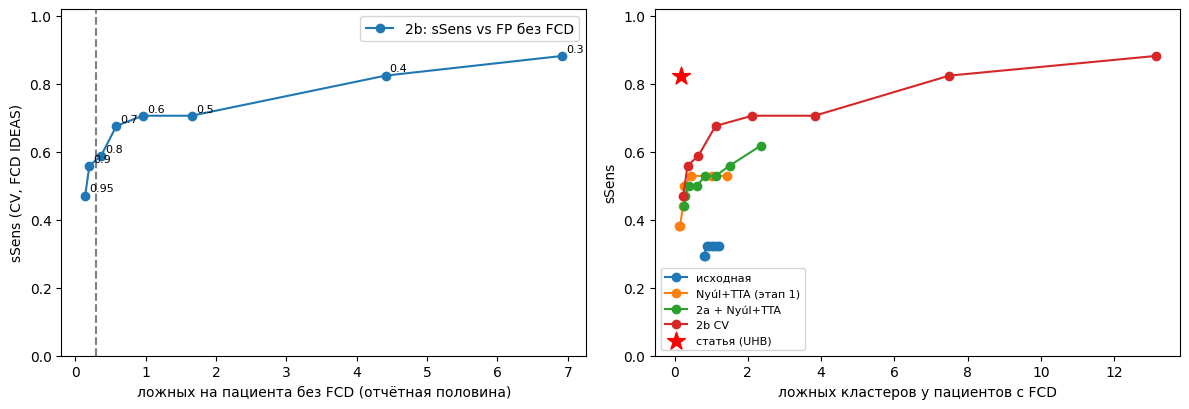

In [11]:
rng = np.random.default_rng(SEED + 1)
all_neg = sorted(s for v in neg_ids.values() for s in v); rng.shuffle(all_neg)
calib, final = set(all_neg[: len(all_neg) // 2]), set(all_neg[len(all_neg) // 2:])

cv_neg, ens_neg = neg["2b CV"], neg["2b ансамбль"]
fcd_cv = ev[ev.variant == "2b CV"]
tab = []
for p in POSTS:
    s = ml.summarize(fcd_cv[fcd_cv.post == p.label]).iloc[0]
    def fp(e, part):
        x = e[(e.post == p.label) & e["sub"].isin(part)].groupby("sub").n_clusters.mean()
        return x.mean(), 100 * (x == 0).mean()
    (fc, _), (ff, zf), (fe, ze) = fp(cv_neg, calib), fp(cv_neg, final), fp(ens_neg, final)
    tab.append(dict(порог=p.thr, sSens=s.sSens, top1=s.top1, top3=s.top3, nFPC_у_FCD=s.nFPC, FP_калибр=fc, FP_отчёт=ff,
                    без_ложных_отчёт_проц=zf, FP_ансамбль_отчёт=fe, без_ложных_ансамбль_проц=ze))
tab = pd.DataFrame(tab).set_index("порог").round(3)
ok_thr = tab[tab.FP_калибр <= TARGET_FP_NEG]
THR = float(ok_thr.sort_values(["sSens", "top1"], ascending=False).index[0]) if len(ok_thr) else float(tab.FP_калибр.idxmin())
display(tab.style.apply(lambda r: ["background: #d4edda" if r.name == THR else "" for _ in r], axis=1))
print(f"Выбран порог {THR}: макс. sSens при FP ≤ {TARGET_FP_NEG} на калибровочной половине (если недостижимо — минимум FP).")

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ax[0].plot(tab.FP_отчёт, tab.sSens, "o-", label="2b: sSens vs FP без FCD")
for t, r in tab.iterrows(): ax[0].annotate(f"{t}", (r.FP_отчёт, r.sSens), xytext=(3, 3), textcoords="offset points", fontsize=8)
ax[0].axvline(TARGET_FP_NEG, ls="--", c="grey"); ax[0].set_xlabel("ложных на пациента без FCD (отчётная половина)")
ax[0].set_ylabel("sSens (CV, FCD IDEAS)"); ax[0].set_ylim(0, 1.02); ax[0].legend()
for v, d in ev[ev.post.isin([p.label for p in POSTS])].groupby("variant", sort=False):
    sw = ml.summarize(d); ax[1].plot(sw.nFPC, sw.sSens, "o-", label=v)
ax[1].scatter([ml.PAPER["nFPC"]], [ml.PAPER["sSens"]], marker="*", s=180, c="red", label="статья (UHB)")
ax[1].set_xlabel("ложных кластеров у пациентов с FCD"); ax[1].set_ylabel("sSens"); ax[1].set_ylim(0, 1.02); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig(IDEAS.out_dir / "stage2b_operating_point.png", dpi=110); plt.show()
tab.to_csv(IDEAS.out_dir / "stage2b_operating_point.csv"); ev.to_csv(IDEAS.out_dir / "stage2b_fcd_cv.csv", index=False)

## 10. Экспорт итоговой модели и вызов для новых пациентов

In [ ]:
DEPLOY = PROJ / "deploy"; DEPLOY.mkdir(exist_ok=True)
import shutil as _sh
for k in range(K_FOLDS): _sh.copy(CKPT / f"fold{k}" / "final.pt", DEPLOY / f"fold{k}.pt")
np.save(DEPLOY / "nyul_ref_uhb.npy", NYUL_REF)
cfg = dict(models=[f"fold{k}.pt" for k in range(K_FOLDS)], nyul_ref="nyul_ref_uhb.npy", tta=True,
           post=dict(thr=THR, brain=True, dilate_mm=3, min_vox=100, topk=None), show_top=3, qc_rules=ml.QC_RULES,
           trained_on="UHB ds004199 (85 FCD II, 40 HC) + IDEAS ds005602 (34 FCD, 60 non-FCD), 5-fold",
           operating_point=tab.loc[THR].to_dict(), date=time.strftime("%Y-%m-%d"))
json.dump(cfg, open(DEPLOY / "config.json", "w"), indent=1, ensure_ascii=False, default=float)
print("Сохранено в", DEPLOY, ":", sorted(p.name for p in DEPLOY.iterdir()))

MNI_ARR = nib.load(MNI).get_fdata(dtype=np.float32); BRAIN_REF = MNI_ARR > np.percentile(MNI_ARR[MNI_ARR > 0], 10)
POST_DEPLOY = ml.Post(**cfg["post"])

def predict_new(t1_path, flair_path, sub_id="sub-new", out_root=PROJ / "predictions"):
    """Новый пациент: FSL → QC → ансамбль (Nyúl+TTA) → кандидаты. Возвращает (QC, таблица кандидатов, путь к карте)."""
    NEW = ml.Dataset("NEW", "-", Path(out_root) / "data", Path(out_root) / "work", Path(out_root) / "out")
    NEW.files = {sub_id: dict(t1=Path(t1_path), flair=Path(flair_path), mask=None)}
    r = ml.run_pipeline(NEW, [sub_id], infer=infer_ens, harmonizer=NYUL, variant="ensemble", mni=MNI, n_fsl=1,
                        wait_cool=wait_cool, progress=False)
    if r["failures"]: raise RuntimeError(r["failures"])
    qc = ml.input_qc(t1_path, flair_path, NEW.fsl(sub_id) / "t1_reg.nii.gz", MNI_ARR, BRAIN_REF, cfg["qc_rules"])
    img = nib.load(NEW.pred("ensemble") / f"{sub_id}_prob.nii.gz")
    brain = nib.load(NEW.ref / f"{sub_id}_brain.nii.gz").get_fdata() > 0
    cands = ml.cluster_table(img.get_fdata(dtype=np.float32), brain, POST_DEPLOY, img.affine, top=cfg["show_top"])
    print(("вход в норме" if qc["ok"] else "!" + "; ".join(qc["flags"])), f"| кандидатов: {len(cands)}")
    return qc, cands, NEW.pred("ensemble") / f"{sub_id}_prob.nii.gz"

# пример: отложенный пациент без FCD (ожидается 0 кандидатов)
demo = next(s for d, s in NEG_TEST if d is IDEAS)
qc, cands, path = predict_new(ml._local(IDEAS, IDEAS.files[demo]["t1"]), ml._local(IDEAS, IDEAS.files[demo]["flair"]), demo)
print(qc); display(cands)

Сохранено в /home/trocinskayayv/projects/mri/ms_dsa_net/deploy : ['config.json', 'fold0.pt', 'fold1.pt', 'fold2.pt', 'fold3.pt', 'fold4.pt', 'nyul_ref_uhb.npy']
[NEW/ensemble] 286.3 мин | готово 1 | ошибок 0
✅ вход в норме | кандидатов: 0
{'t1_mm': 1.2000000476837158, 'flair_mm': 2.0, 'flags': [], 'mni_corr': 0.6007110364587079, 'ok': True}


,peak_prob,volume_ml,x,y,z


## 11. Кривые обучения по фолдам

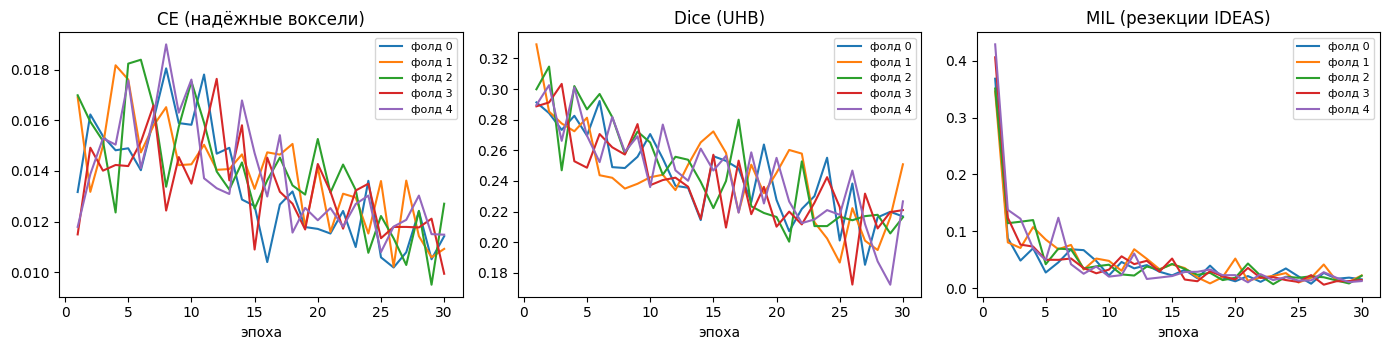

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
for k in range(K_FOLDS):
    f = CKPT / f"fold{k}" / "log.csv"
    if not f.exists(): continue
    lg = pd.read_csv(f)
    for a, c in zip(ax, ("ce", "dice", "mil")): a.plot(lg.epoch, lg[c], label=f"фолд {k}")
for a, c in zip(ax, ("CE (надёжные воксели)", "Dice (UHB)", "MIL (резекции IDEAS)")): a.set_title(c); a.set_xlabel("эпоха"); a.legend(fontsize=8)
plt.tight_layout(); plt.savefig(CKPT / "curves.png", dpi=110); plt.show()